In [2]:
%pip install torch numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [5]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader, random_split

In [9]:
from pathlib import Path

# 현재 작업 폴더 확인
print("현재 폴더:", Path.cwd())

# 현재 폴더에 있는 npz 파일 확인
print("데이터셋 파일 목록:")

for file in Path.cwd().glob("*.npz"):
    print(file.name)

현재 폴더: c:\Users\user\Desktop\sangwoo\1016
데이터셋 파일 목록:
member_A_mnist_processed.npz


In [10]:
data = np.load("member_A_mnist_processed.npz")

In [11]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torchvision

from torchvision import datasets

In [12]:
# MNIST 데이터셋 다운로드
mnist_train = datasets.MNIST(
    root="./data",
    train=True,
    download=True
)

# 이미지 100장 가져오기
images = mnist_train.data[:100].numpy()

# 정답 100개 가져오기
labels = mnist_train.targets[:100].numpy()

# 정규화 (0~255를 0~1로 변경)
images = images.astype(np.float32) / 255.0

print("이미지:", images.shape)
print("정답:", labels.shape)

100.0%
100.0%
100.0%
100.0%

이미지: (100, 28, 28)
정답: (100,)


In [13]:
# ① 패딩 적용
padding_images = np.pad(
    images,
    ((0, 0), (1, 1), (1, 1)),
    mode="constant",
    constant_values=0
)


# ② 3×3 평균 커널 만들기
kernel = np.ones((3, 3), dtype=np.float32) / 9

kernel_images = np.zeros_like(images)

for n in range(len(images)):
    for row in range(28):
        for col in range(28):

            area = padding_images[
                n,
                row:row+3,
                col:col+3
            ]

            kernel_images[n, row, col] = np.sum(
                area * kernel
            )


# ③ 2×2 Max Pooling
pooling_images = np.zeros(
    (len(images), 14, 14),
    dtype=np.float32
)

for n in range(len(images)):
    for row in range(14):
        for col in range(14):

            area = kernel_images[
                n,
                row*2:row*2+2,
                col*2:col*2+2
            ]

            pooling_images[n, row, col] = np.max(area)


# 결과 확인
print("원본:", images.shape)
print("패딩:", padding_images.shape)
print("커널:", kernel_images.shape)
print("풀링:", pooling_images.shape)

원본: (100, 28, 28)
패딩: (100, 30, 30)
커널: (100, 28, 28)
풀링: (100, 14, 14)


In [14]:
np.savez_compressed(
    "my_mnist_dataset.npz",
    original=images,
    labels=labels,
    padding=padding_images,
    kernel=kernel_images,
    pooling=pooling_images
)

print("데이터셋 저장 완료!")
print("저장 위치:", Path("my_mnist_dataset.npz").resolve())

데이터셋 저장 완료!
저장 위치: C:\Users\user\Desktop\sangwoo\1016\my_mnist_dataset.npz


In [15]:
data = np.load("my_mnist_dataset.npz")

print(data.files)

print("원본:", data["original"].shape)
print("패딩:", data["padding"].shape)
print("커널:", data["kernel"].shape)
print("풀링:", data["pooling"].shape)
print("정답:", data["labels"].shape)

['original', 'labels', 'padding', 'kernel', 'pooling']
원본: (100, 28, 28)
패딩: (100, 30, 30)
커널: (100, 28, 28)
풀링: (100, 14, 14)
정답: (100,)


In [16]:
from torch.utils.data import Dataset, DataLoader, random_split

class MyMNISTDataset(Dataset):

    def __init__(self, file_path):

        # 데이터셋 파일 불러오기
        with np.load(file_path) as data:
            images = data["pooling"].copy()
            labels = data["labels"].copy()

        # NumPy 배열을 PyTorch 텐서로 변환
        self.images = torch.tensor(
            images,
            dtype=torch.float32
        ).unsqueeze(1)

        self.labels = torch.tensor(
            labels,
            dtype=torch.long
        )

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        return self.images[index], self.labels[index]


# 클래스 실행
dataset = MyMNISTDataset("my_mnist_dataset.npz")

print("데이터 개수:", len(dataset))
print("이미지 크기:", dataset[0][0].shape)
print("정답:", dataset[0][1].item())

데이터 개수: 100
이미지 크기: torch.Size([1, 14, 14])
정답: 5


In [27]:
# 전체 데이터의 80%를 학습용으로 사용
train_size = int(len(dataset) * 0.8)

# 나머지는 검증용
val_size = len(dataset) - train_size

# 데이터 나누기
train_set, val_set = random_split(
    dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

# 학습용 DataLoader
trainloader = DataLoader(
    train_set,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

# 검증용 DataLoader
valloader = DataLoader(
    val_set,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("학습 데이터:", len(train_set))
print("검증 데이터:", len(val_set))

학습 데이터: 80
검증 데이터: 20


In [39]:
import torch.nn as nn
import torch.nn.functional as F

class MNISTCNN(nn.Module):

    def __init__(self):
        super().__init__()

        # 첫 번째 합성곱 층
        self.conv1 = nn.Conv2d(
            1, 8, kernel_size=3, padding=1
        )

        # 최대 풀링
        self.pool = nn.MaxPool2d(2, 2)

        # 두 번째 합성곱 층
        self.conv2 = nn.Conv2d(
            8, 16, kernel_size=3, padding=1
        )

        # 완전연결층
        self.fc1 = nn.Linear(16 * 3 * 3, 32)
        self.fc2 = nn.Linear(32, 10)

    def forward(self, x):

        # 첫 번째 CNN 연산
        x = self.pool(F.relu(self.conv1(x)))

        # 두 번째 CNN 연산
        x = self.pool(F.relu(self.conv2(x)))

        # 1차원으로 펼치기
        x = torch.flatten(x, 1)

        # 완전연결층
        x = F.relu(self.fc1(x))

        # 최종 출력
        x = self.fc2(x)

        return x


# 모델 생성
torch.manual_seed(42)
net = MNISTCNN()

print(net)

MNISTCNN(
  (conv1): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=144, out_features=32, bias=True)
  (fc2): Linear(in_features=32, out_features=10, bias=True)
)


In [43]:
import torch.optim as optim

# 손실함수
criterion = nn.CrossEntropyLoss()

# 옵티마이저
optimizer = optim.Adam(
    net.parameters(),
    lr=0.0001
)

In [44]:
# 전체 학습 반복 횟수
epochs = 15

# Loss 저장
train_losses = []
val_losses = []

for epoch in range(epochs):

    # 학습 모드
    net.train()

    running_loss = 0.0

    for images, labels in trainloader:

        # 기울기 초기화
        optimizer.zero_grad()

        # 예측
        outputs = net(images)

        # Loss 계산
        loss = criterion(outputs, labels)

        # 역전파
        loss.backward()

        # 가중치 수정
        optimizer.step()

        # Loss 누적
        running_loss += loss.item() * images.size(0)

    # 학습 Loss 계산
    train_loss = running_loss / len(train_set)
    train_losses.append(train_loss)

    # 검증 모드
    net.eval()

    val_loss_sum = 0.0
    correct = 0

    with torch.no_grad():

        for images, labels in valloader:

            outputs = net(images)

            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()

    val_loss = val_loss_sum / len(val_set)
    val_accuracy = correct / len(val_set) * 100

    val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.1f}%"
    )

print("Finished Training")

Epoch [1/15] Train Loss: 2.2334 | Val Loss: 2.4991 | Val Accuracy: 0.0%
Epoch [2/15] Train Loss: 2.2334 | Val Loss: 2.4990 | Val Accuracy: 0.0%
Epoch [3/15] Train Loss: 2.2334 | Val Loss: 2.4991 | Val Accuracy: 0.0%
Epoch [4/15] Train Loss: 2.2334 | Val Loss: 2.4991 | Val Accuracy: 0.0%
Epoch [5/15] Train Loss: 2.2334 | Val Loss: 2.4990 | Val Accuracy: 0.0%
Epoch [6/15] Train Loss: 2.2334 | Val Loss: 2.4989 | Val Accuracy: 0.0%
Epoch [7/15] Train Loss: 2.2334 | Val Loss: 2.4990 | Val Accuracy: 0.0%
Epoch [8/15] Train Loss: 2.2334 | Val Loss: 2.4990 | Val Accuracy: 0.0%
Epoch [9/15] Train Loss: 2.2334 | Val Loss: 2.4989 | Val Accuracy: 0.0%
Epoch [10/15] Train Loss: 2.2334 | Val Loss: 2.4990 | Val Accuracy: 0.0%
Epoch [11/15] Train Loss: 2.2334 | Val Loss: 2.4989 | Val Accuracy: 0.0%
Epoch [12/15] Train Loss: 2.2334 | Val Loss: 2.4989 | Val Accuracy: 0.0%
Epoch [13/15] Train Loss: 2.2334 | Val Loss: 2.4989 | Val Accuracy: 0.0%
Epoch [14/15] Train Loss: 2.2334 | Val Loss: 2.4988 | Val Ac

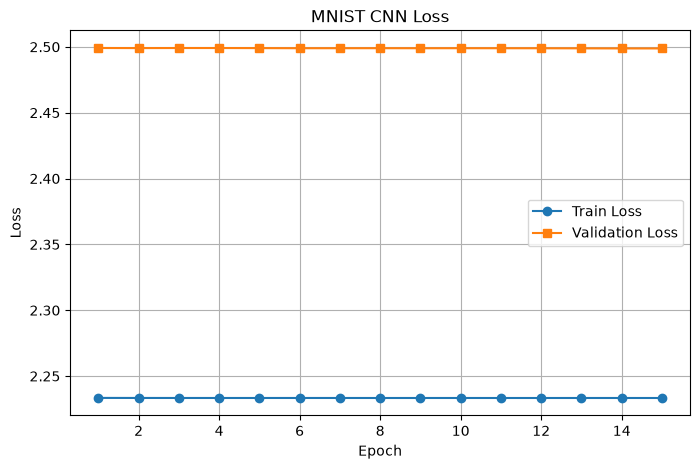

In [45]:
plt.figure(figsize=(8, 5))

# 학습 Loss
plt.plot(
    range(1, epochs + 1),
    train_losses,
    label="Train Loss",
    marker="o"
)

# 검증 Loss
plt.plot(
    range(1, epochs + 1),
    val_losses,
    label="Validation Loss",
    marker="s"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MNIST CNN Loss")

plt.legend()
plt.grid(True)
plt.show()

In [22]:
torch.save(
    net.state_dict(),
    "mnist_cnn.pth"
)

print("CNN 모델 저장 완료!")

CNN 모델 저장 완료!


In [46]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torchvision import datasets
from torch.utils.data import Dataset, DataLoader, random_split

from pathlib import Path

In [47]:
# 1. MNIST 불러오기
mnist_train = datasets.MNIST(
    root="./data",
    train=True,
    download=True
)

# 2. 원본 이미지 5,000장 가져오기
images = mnist_train.data[:5000].numpy()
labels = mnist_train.targets[:5000].numpy()

# 3. 정규화
images = images.astype(np.float32) / 255.0

# 4. 패딩
padding_images = np.pad(
    images,
    ((0, 0), (1, 1), (1, 1)),
    mode="constant",
    constant_values=0
)

# 5. 3×3 평균 커널 적용
# PyTorch를 사용해 빠르게 계산
padded_tensor = torch.from_numpy(
    padding_images
).unsqueeze(1)

kernel_images = F.avg_pool2d(
    padded_tensor,
    kernel_size=3,
    stride=1
).squeeze(1).numpy()

# 6. 2×2 Max Pooling
kernel_tensor = torch.from_numpy(
    kernel_images
).unsqueeze(1)

pooling_images = F.max_pool2d(
    kernel_tensor,
    kernel_size=2,
    stride=2
).squeeze(1).numpy()

# 7. 데이터셋 저장
np.savez_compressed(
    "my_mnist_dataset_5000.npz",
    original=images,
    labels=labels,
    padding=padding_images,
    kernel=kernel_images,
    pooling=pooling_images
)

print("원본:", images.shape)
print("패딩:", padding_images.shape)
print("커널:", kernel_images.shape)
print("풀링:", pooling_images.shape)

print("저장 완료!")
print(Path("my_mnist_dataset_5000.npz").resolve())

원본: (5000, 28, 28)
패딩: (5000, 30, 30)
커널: (5000, 28, 28)
풀링: (5000, 14, 14)
저장 완료!
C:\Users\user\Desktop\sangwoo\1016\my_mnist_dataset_5000.npz


In [48]:
class MyMNISTDataset(Dataset):

    def __init__(self, file_path, stage="original"):

        # 저장한 데이터셋 불러오기
        with np.load(file_path) as data:
            images = data[stage].astype(np.float32)
            labels = data["labels"].astype(np.int64)

        # PyTorch Tensor로 변경
        self.images = torch.from_numpy(
            images
        ).unsqueeze(1)

        self.labels = torch.from_numpy(labels)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        return self.images[index], self.labels[index]


# 여기서 사용할 이미지 선택!
STAGE = "original"

dataset = MyMNISTDataset(
    "my_mnist_dataset_5000.npz",
    stage=STAGE
)

# 80% 학습, 20% 검증
train_size = int(len(dataset) * 0.8)
val_size = len(dataset) - train_size

train_set, val_set = random_split(
    dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

# DataLoader
trainloader = DataLoader(
    train_set,
    batch_size=64,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(42)
)

valloader = DataLoader(
    val_set,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

print("학습 데이터:", len(train_set))
print("검증 데이터:", len(val_set))

sample_image, sample_label = dataset[0]
print("첫 번째 이미지:", sample_image.shape)
print("정답:", sample_label.item())

학습 데이터: 4000
검증 데이터: 1000
첫 번째 이미지: torch.Size([1, 28, 28])
정답: 5


In [49]:
class MNISTCNN(nn.Module):

    def __init__(self):
        super().__init__()

        # 첫 번째 합성곱
        self.conv1 = nn.Conv2d(
            1, 16, kernel_size=3, padding=1
        )

        # 최대 풀링
        self.pool = nn.MaxPool2d(2, 2)

        # 두 번째 합성곱
        self.conv2 = nn.Conv2d(
            16, 32, kernel_size=3, padding=1
        )

        # 이미지 크기를 3×3으로 맞추기
        self.adaptive = nn.AdaptiveAvgPool2d((3, 3))

        # 완전연결층
        self.fc1 = nn.Linear(32 * 3 * 3, 64)
        self.fc2 = nn.Linear(64, 10)

    def forward(self, x):

        # 첫 번째 CNN 연산
        x = self.pool(F.relu(self.conv1(x)))

        # 두 번째 CNN 연산
        x = self.pool(F.relu(self.conv2(x)))

        # 크기 맞추기
        x = self.adaptive(x)

        # 1차원으로 펼치기
        x = torch.flatten(x, 1)

        # 숫자 분류
        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x


# 새 모델 만들기
torch.manual_seed(42)
net = MNISTCNN()

# Loss 함수
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    net.parameters(),
    lr=0.001
)

print(net)

MNISTCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (adaptive): AdaptiveAvgPool2d(output_size=(3, 3))
  (fc1): Linear(in_features=288, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=10, bias=True)
)


In [50]:
# 학습 반복 횟수
EPOCHS = 20

# 학습 결과 저장
train_losses = []
val_losses = []
val_accuracies = []

for epoch in range(EPOCHS):

    # 1. 학습 모드
    net.train()

    total_train_loss = 0.0

    for images, labels in trainloader:

        # 기울기 초기화
        optimizer.zero_grad()

        # CNN 예측
        outputs = net(images)

        # Loss 계산
        loss = criterion(outputs, labels)

        # 역전파
        loss.backward()

        # 가중치 수정
        optimizer.step()

        # 손실 누적
        total_train_loss += loss.item() * images.size(0)

    # 평균 학습 Loss
    train_loss = total_train_loss / len(train_set)
    train_losses.append(train_loss)

    # 2. 검증 모드
    net.eval()

    total_val_loss = 0.0
    correct = 0

    with torch.no_grad():

        for images, labels in valloader:

            outputs = net(images)

            loss = criterion(outputs, labels)

            total_val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()

    # 평균 검증 Loss
    val_loss = total_val_loss / len(val_set)

    # 검증 정확도
    val_accuracy = correct / len(val_set) * 100

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Accuracy: {val_accuracy:.1f}%"
    )

print("Finished Training")

Epoch 1/20 | Train Loss: 2.2450 | Val Loss: 2.0609 | Accuracy: 33.7%
Epoch 2/20 | Train Loss: 1.4245 | Val Loss: 1.0054 | Accuracy: 67.4%
Epoch 3/20 | Train Loss: 0.7239 | Val Loss: 0.6139 | Accuracy: 80.9%
Epoch 4/20 | Train Loss: 0.4906 | Val Loss: 0.4830 | Accuracy: 85.0%
Epoch 5/20 | Train Loss: 0.3854 | Val Loss: 0.3812 | Accuracy: 88.4%
Epoch 6/20 | Train Loss: 0.3315 | Val Loss: 0.3583 | Accuracy: 88.0%
Epoch 7/20 | Train Loss: 0.3009 | Val Loss: 0.3029 | Accuracy: 91.4%
Epoch 8/20 | Train Loss: 0.2716 | Val Loss: 0.3122 | Accuracy: 90.2%
Epoch 9/20 | Train Loss: 0.2567 | Val Loss: 0.2804 | Accuracy: 91.1%
Epoch 10/20 | Train Loss: 0.2454 | Val Loss: 0.2694 | Accuracy: 92.5%
Epoch 11/20 | Train Loss: 0.2214 | Val Loss: 0.2307 | Accuracy: 93.3%
Epoch 12/20 | Train Loss: 0.2166 | Val Loss: 0.2233 | Accuracy: 93.4%
Epoch 13/20 | Train Loss: 0.1941 | Val Loss: 0.2100 | Accuracy: 94.2%
Epoch 14/20 | Train Loss: 0.1840 | Val Loss: 0.2135 | Accuracy: 94.6%
Epoch 15/20 | Train Loss: 0.1

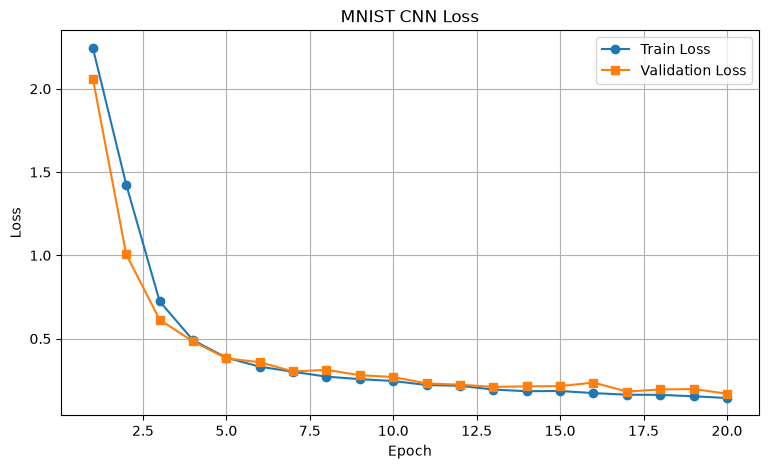

In [51]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_losses,
    label="Train Loss",
    marker="o"
)

plt.plot(
    range(1, EPOCHS + 1),
    val_losses,
    label="Validation Loss",
    marker="s"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MNIST CNN Loss")

plt.legend()
plt.grid(True)
plt.show()

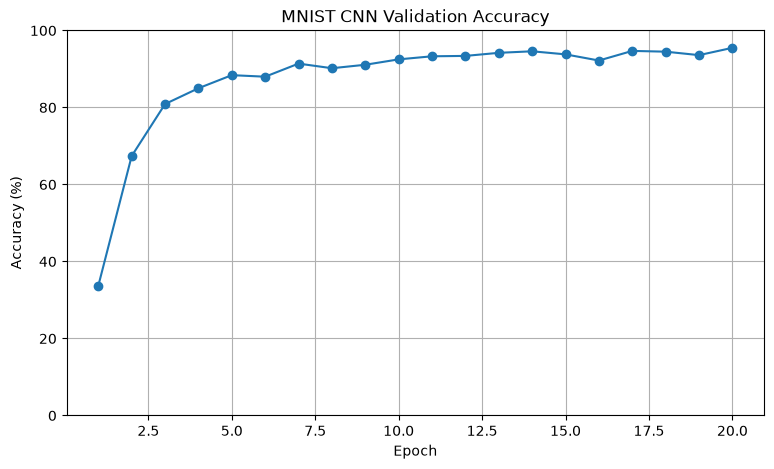

In [52]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, EPOCHS + 1),
    val_accuracies,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("MNIST CNN Validation Accuracy")

plt.ylim(0, 100)
plt.grid(True)
plt.show()

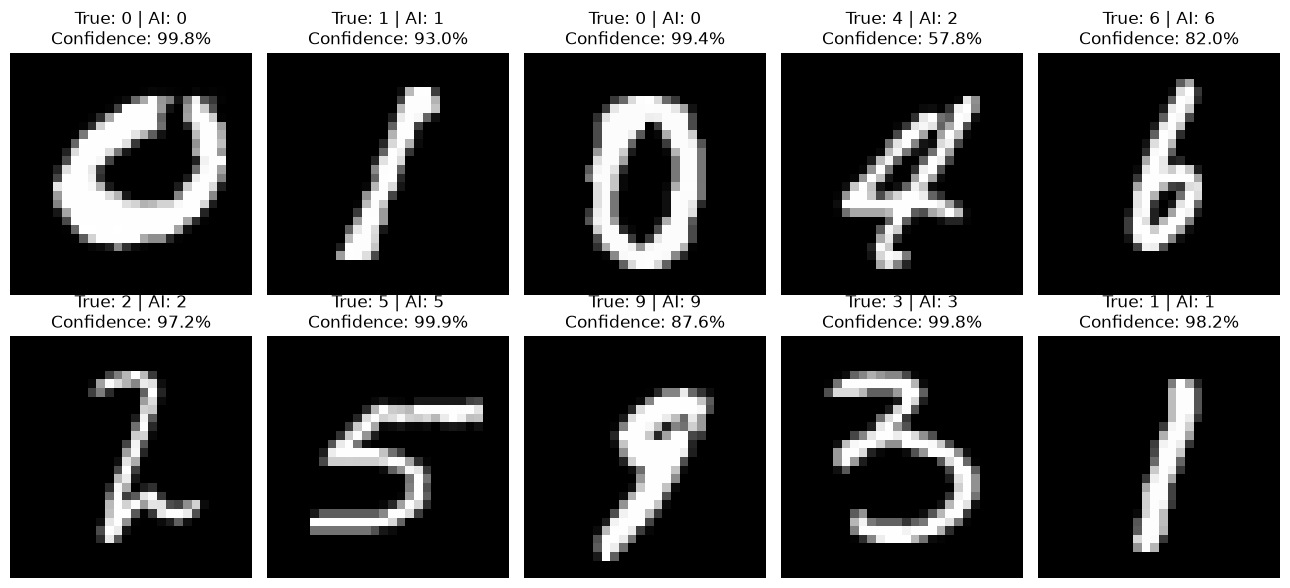

In [53]:
import torch
import matplotlib.pyplot as plt

net.eval()

images, labels = next(iter(valloader))

device = next(net.parameters()).device

with torch.no_grad():
    outputs = net(images.to(device))
    probs = torch.softmax(outputs, dim=1)
    predictions = probs.argmax(dim=1)

fig, axes = plt.subplots(2, 5, figsize=(13, 6))

for i, ax in enumerate(axes.flat):
    img = images[i].cpu().squeeze().numpy()

    actual = labels[i].item()
    predicted = predictions[i].item()
    confidence = probs[i, predicted].item()

    ax.imshow(img, cmap="gray")
    ax.set_title(
        f"True: {actual} | AI: {predicted}\n"
        f"Confidence: {confidence:.1%}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()